# Hospital Queue Analytics — Exploratory Data Analysis
Analysis of 90 days of outpatient (OPD) queue data from the **AI Smart Hospital Queue
Management System**. Goal: find operational bottlenecks in waiting time, doctor workload
and patient flow, and quantify the effect of the app's severity-priority queue.

> Data is synthetic (generated by `src/generate_data.py` to mirror the app's database
> schema) because real patient records cannot be published. See README for details.

In [1]:
import sqlite3
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#d6d5d0", "grid.color": "#ecebe7",
              "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
              "axes.titleweight": "bold", "figure.dpi": 110})
FIG = "../reports/figures/"
con = sqlite3.connect("../data/processed/hospital_queue.db")
df = pd.read_sql_query('''
    SELECT f.*, d.department_name AS department, dt.day_name, dt.day_of_week, dt.full_date
    FROM fact_appointment f
    JOIN dim_department d ON d.department_id = f.department_id
    JOIN dim_date dt ON dt.date_key = f.date_key''', con, parse_dates=["created_at", "full_date"])
seen = df[df.status != "cancelled"]
served = df[df.status == "completed"]
df.shape

(27706, 21)

## 1. Data overview & quality

In [2]:
display(df.head())
display(df.describe(include="number").T.round(2))
print(df.status.value_counts(normalize=True).round(3))
pd.read_csv("../reports/data_quality_log.csv")

,appointment_id,date_key,arrival_hour,created_at,patient_id,department_id,doctor_id,token_number,age,gender,...,fever,spo2,bp_systolic,status,waiting_time_min,consult_duration_min,department,day_name,day_of_week,full_date
0,A000001,20260101,8,2026-01-01 08:07:18,P04377,1,DOC06,1,54,F,...,36.0,97.0,149,completed,0.0,16.6,Cardiology,Thursday,4,2026-01-01
1,A000002,20260101,8,2026-01-01 08:07:55,P03961,5,DOC08,1,26,M,...,37.1,98.0,125,completed,0.0,14.5,Orthopedics,Thursday,4,2026-01-01
2,A000003,20260101,8,2026-01-01 08:08:52,P00216,4,DOC01,1,50,F,...,39.1,96.0,103,completed,0.0,11.5,General Medicine,Thursday,4,2026-01-01
3,A000004,20260101,8,2026-01-01 08:20:19,P02323,5,DOC09,2,32,M,...,36.8,97.0,152,completed,0.0,8.8,Orthopedics,Thursday,4,2026-01-01
4,A000005,20260101,8,2026-01-01 08:20:26,P04848,4,DOC01,2,30,F,...,36.7,98.0,131,completed,0.0,10.8,General Medicine,Thursday,4,2026-01-01


,count,mean,std,min,25%,50%,75%,max
date_key,27706.0,20260216.78,83.30,20260101.0,20260123.0,20260216.0,20260309.0,20260331.0
arrival_hour,27706.0,12.63,3.33,8.0,10.0,12.0,16.0,19.0
department_id,27706.0,4.16,1.63,1.0,4.0,4.0,5.0,7.0
token_number,27706.0,39.77,38.23,1.0,12.0,25.0,56.0,184.0
age,27706.0,37.05,20.62,0.0,19.0,38.0,52.0,95.0
severity_score,27706.0,1.72,0.79,1.0,1.0,2.0,2.0,5.0
fever,27706.0,37.64,0.92,36.0,37.0,37.6,38.3,41.1
spo2,27706.0,96.45,1.99,85.0,95.0,97.0,98.0,100.0
bp_systolic,27706.0,127.35,17.46,75.0,116.0,127.0,139.0,196.0
waiting_time_min,26914.0,9.07,21.05,0.0,0.0,0.0,7.8,230.9


status
completed    0.917
no_show      0.055
cancelled    0.029
Name: proportion, dtype: float64


,step,rows_affected,note
0,extract: raw rows,27872,NaN
1,remove duplicate submissions,166,NaN
2,standardise department labels,1173,NaN
3,unmapped departments (dropped),0,NaN
4,convert fever F -> C,549,values > 45 treated as Fahrenheit
5,invalid SpO2 -> null,83,outside 50-100%
6,invalid age -> null,55,outside 0-110
7,impute missing fever (dept median),277,NaN
8,impute missing spo2 (dept median),497,NaN
9,impute missing age (dept median),55,NaN


## 2. Waiting-time distribution
Waiting time is heavily right-skewed: most patients are seen quickly, a long tail waits 30+ min.

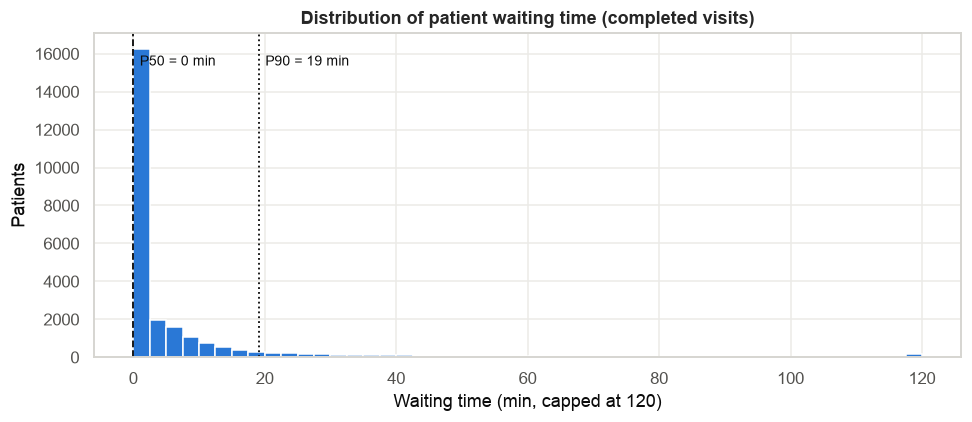

count    25394.0
mean         7.4
std         18.9
min          0.0
50%          0.0
75%          6.2
90%         19.1
95%         38.6
max        213.3
Name: waiting_time_min, dtype: float64


In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(served.waiting_time_min.clip(upper=120), bins=48, color=BLUE, edgecolor="white", linewidth=1)
for q, ls in [(0.5, "--"), (0.9, ":")]:
    v = served.waiting_time_min.quantile(q)
    ax.axvline(v, color=INK, ls=ls, lw=1.2)
    ax.text(v + 1, ax.get_ylim()[1] * 0.9, f"P{int(q*100)} = {v:.0f} min", color=INK, fontsize=9)
ax.set(title="Distribution of patient waiting time (completed visits)", xlabel="Waiting time (min, capped at 120)", ylabel="Patients")
plt.tight_layout(); plt.savefig(FIG + "01_wait_distribution.png"); plt.show()
print(served.waiting_time_min.describe(percentiles=[.5, .75, .9, .95]).round(1))

## 3. Bottleneck 1 — General Medicine is under-staffed relative to demand

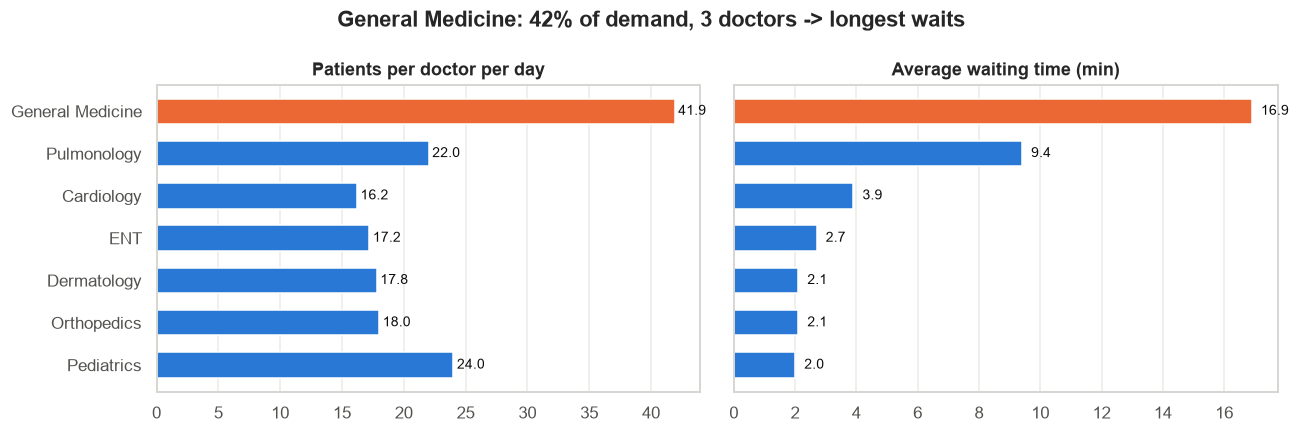

,department_name,doctors,avg_daily_visits,visits_per_doctor_day,avg_wait_min,pct_over_30min,no_show_pct,wait_rank
0,General Medicine,3,125.8,41.9,16.9,18.3,11.3,1
1,Pulmonology,1,22.0,22.0,9.4,8.8,4.9,2
2,Cardiology,2,32.3,16.2,3.9,2.4,1.5,3
3,ENT,1,17.2,17.2,2.7,0.6,1.7,4
4,Orthopedics,2,36.0,18.0,2.1,0.8,0.7,5
5,Dermatology,1,17.8,17.8,2.1,0.5,1.1,6
6,Pediatrics,2,48.0,24.0,2.0,0.7,0.8,7


In [4]:
dept = pd.read_csv("../reports/sql_results/02_department_bottlenecks.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
order = dept.sort_values("avg_wait_min").department_name
d = dept.set_index("department_name").loc[order]
for ax, col, title in [(axes[0], "visits_per_doctor_day", "Patients per doctor per day"),
                       (axes[1], "avg_wait_min", "Average waiting time (min)")]:
    colors = [ORANGE if n == "General Medicine" else BLUE for n in d.index]
    ax.barh(d.index, d[col], color=colors, height=0.6)
    for y, v in enumerate(d[col]): ax.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=9, color=INK)
    ax.set_title(title); ax.grid(axis="y", visible=False)
fig.suptitle("General Medicine: 42% of demand, 3 doctors -> longest waits", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG + "02_department_bottleneck.png"); plt.show()
dept

## 4. Bottleneck 2 & 3 — Morning rush and Monday surge

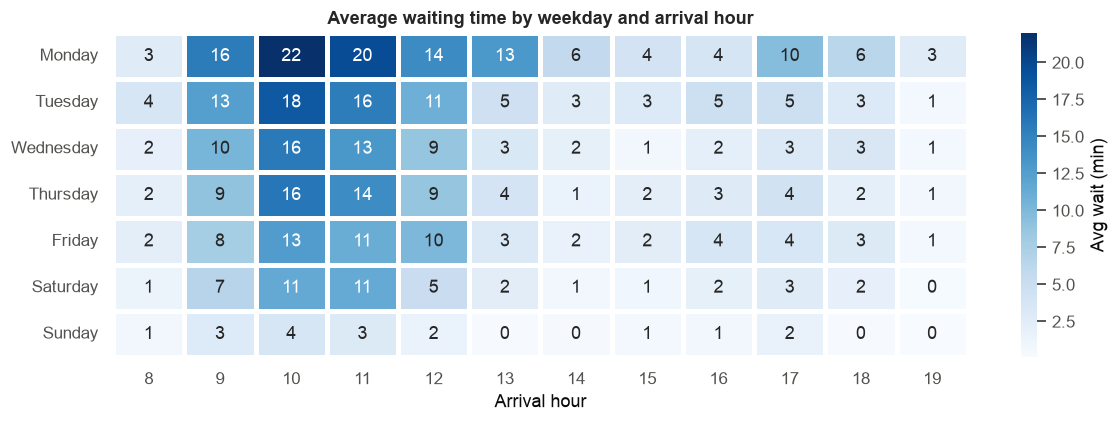

09:00-12:59 receives 48% of all arrivals in 4 of 12 operating hours


In [5]:
heat = served.pivot_table(index="day_name", columns="arrival_hour", values="waiting_time_min", aggfunc="mean")
heat = heat.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(heat, cmap="Blues", annot=True, fmt=".0f", linewidths=2, linecolor="white",
            cbar_kws={"label": "Avg wait (min)"}, ax=ax)
ax.set(title="Average waiting time by weekday and arrival hour", xlabel="Arrival hour", ylabel="")
plt.tight_layout(); plt.savefig(FIG + "03_weekday_hour_heatmap.png"); plt.show()

hourly = pd.read_csv("../reports/sql_results/03_hourly_load.csv")
share = hourly.query("9 <= arrival_hour <= 12").share_of_daily_pct.sum()
print(f"09:00-12:59 receives {share:.0f}% of all arrivals in 4 of 12 operating hours")

/var/folders/bt/7454wz812gd4glv1m8lghhbh0000gn/T/ipykernel_79000/4112933006.py:5: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  mon = daily[daily.full_date.dt.dayofweek == 0]


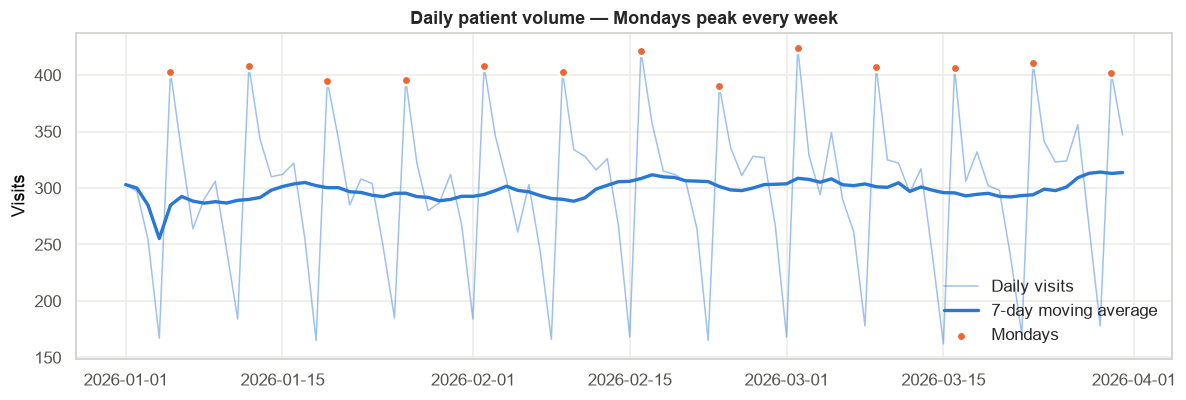

,day_name,avg_daily_visits,avg_wait_min,pct_vs_avg_day
0,Monday,406.0,14.8,35.7
1,Tuesday,335.0,10.5,12.2
2,Wednesday,306.0,8.3,2.3
3,Thursday,307.0,8.6,2.6
4,Friday,313.0,7.4,4.5
5,Saturday,255.0,6.0,-14.7
6,Sunday,172.0,1.9,-42.4


In [6]:
daily = pd.read_csv("../reports/sql_results/08_daily_trend.csv", parse_dates=["full_date"])
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(daily.full_date, daily.visits, color=BLUE, lw=1, alpha=0.45, label="Daily visits")
ax.plot(daily.full_date, daily.visits_7d_ma, color=BLUE, lw=2.2, label="7-day moving average")
mon = daily[daily.full_date.dt.dayofweek == 0]
ax.scatter(mon.full_date, mon.visits, color=ORANGE, s=36, zorder=3, edgecolor="white", linewidth=1.5, label="Mondays")
ax.set(title="Daily patient volume — Mondays peak every week", ylabel="Visits")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(FIG + "04_daily_trend.png"); plt.show()
pd.read_csv("../reports/sql_results/04_weekday_pattern.csv")

## 5. Bottleneck 4 — Doctor workload imbalance & consultation-time variance

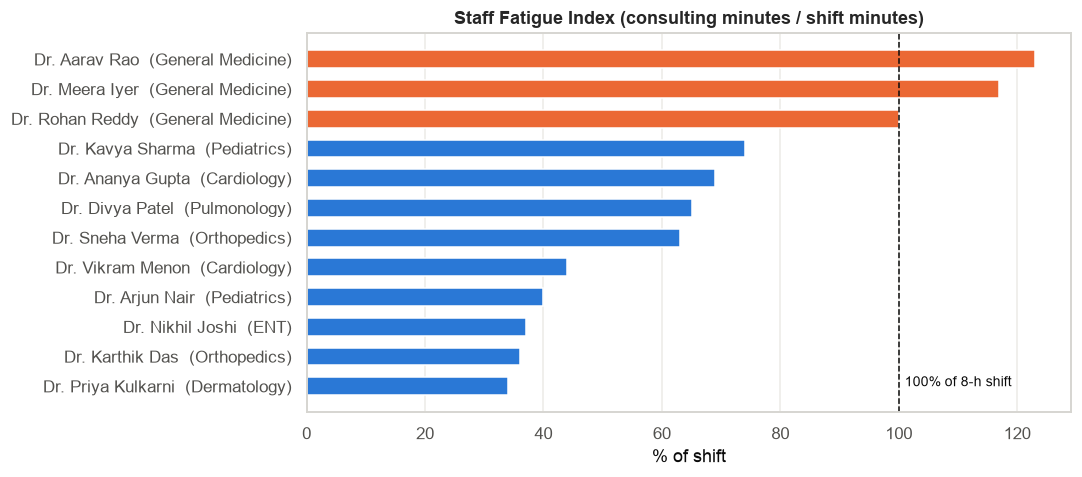

ANOVA consult duration across GM doctors: F=946.6, p=0.00e+00


,name,department_name,patients_per_day,avg_consult_min,fatigue_pct,consult_min_vs_dept_avg,slowest_in_dept
0,Dr. Aarav Rao,General Medicine,45.3,13.0,123.0,-1.9,3
1,Dr. Meera Iyer,General Medicine,30.4,18.4,117.0,3.5,1
2,Dr. Rohan Reddy,General Medicine,35.9,13.3,100.0,-1.6,2
3,Dr. Kavya Sharma,Pediatrics,27.8,12.7,74.0,1.4,1
4,Dr. Ananya Gupta,Cardiology,20.5,16.0,69.0,-1.4,2
5,Dr. Divya Patel,Pulmonology,20.9,15.0,65.0,0.0,1
6,Dr. Sneha Verma,Orthopedics,23.1,13.1,63.0,-0.3,2
7,Dr. Vikram Menon,Cardiology,11.3,18.7,44.0,1.4,1
8,Dr. Arjun Nair,Pediatrics,19.8,9.8,40.0,-1.4,2
9,Dr. Nikhil Joshi,ENT,16.9,10.4,37.0,0.0,1


In [7]:
wl = pd.read_csv("../reports/sql_results/06_doctor_workload.csv")
fig, ax = plt.subplots(figsize=(10, 4.5))
wl = wl.sort_values("fatigue_pct")
colors = [ORANGE if f >= 90 else BLUE for f in wl.fatigue_pct]
ax.barh(wl.name + "  (" + wl.department_name + ")", wl.fatigue_pct, color=colors, height=0.6)
ax.axvline(100, color=INK, ls="--", lw=1); ax.text(101, 0, "100% of 8-h shift", fontsize=9, color=INK)
ax.set(title="Staff Fatigue Index (consulting minutes / shift minutes)", xlabel="% of shift")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG + "05_doctor_fatigue.png"); plt.show()

gm = served[served.department == "General Medicine"]
groups = [g.consult_duration_min.values for _, g in gm.groupby("doctor_id")]
f, p = stats.f_oneway(*groups)
print(f"ANOVA consult duration across GM doctors: F={f:.1f}, p={p:.2e}")
wl.sort_values("fatigue_pct", ascending=False)

## 6. Long waits drive walk-outs (no-shows)

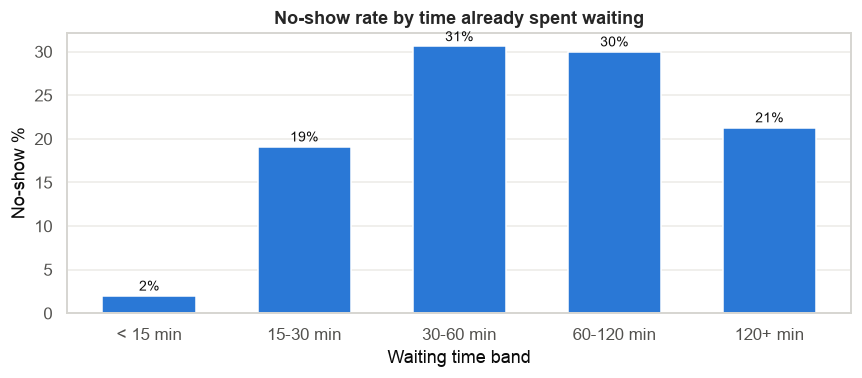

Chi-square (wait > 30 min vs no-show): chi2=2828, p=0.0e+00


In [8]:
band = pd.read_csv("../reports/sql_results/09_no_show_by_wait_band.csv")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(band.wait_band.str[3:], band.no_show_pct, color=BLUE, width=0.6)
for x, v in enumerate(band.no_show_pct): ax.text(x, v + 0.6, f"{v:.0f}%", ha="center", fontsize=9, color=INK)
ax.set(title="No-show rate by time already spent waiting", ylabel="No-show %", xlabel="Waiting time band")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIG + "06_noshow_by_wait.png"); plt.show()

ct = pd.crosstab(seen.waiting_time_min > 30, seen.status == "no_show")
chi2, p, *_ = stats.chi2_contingency(ct)
print(f"Chi-square (wait > 30 min vs no-show): chi2={chi2:.0f}, p={p:.1e}")

## 7. Impact of the severity-priority queue (FIFO vs priority)
Same simulated arrivals replayed under both policies. **Key insight:** the overall
average barely moves (queueing theory: reordering a queue does not create capacity) —
the system *redistributes* waiting time from low-severity to high-severity patients.

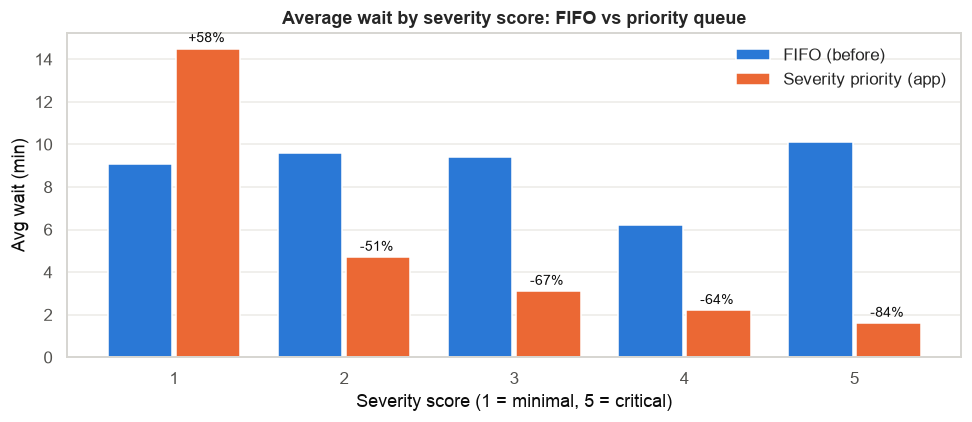

Paired t-test, severity >= 3: mean wait 9.2 -> 3.0 min, t=31.0, p=7.1e-193


In [9]:
pol = pd.read_csv("../reports/sql_results/10_policy_impact_by_severity.csv").dropna()
x = np.arange(len(pol)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w/2 - 0.01, pol.avg_wait_fifo, w, color=BLUE, label="FIFO (before)")
ax.bar(x + w/2 + 0.01, pol.avg_wait_priority, w, color=ORANGE, label="Severity priority (app)")
for i, r in pol.iterrows():
    ax.text(i + w/2, r.avg_wait_priority + 0.3, f"{r["pct_change"]:+.0f}%", ha="center", fontsize=9, color=INK)
ax.set_xticks(x, [f"{int(s)}" for s in pol.severity_score])
ax.set(title="Average wait by severity score: FIFO vs priority queue", xlabel="Severity score (1 = minimal, 5 = critical)", ylabel="Avg wait (min)")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig(FIG + "07_policy_impact.png"); plt.show()

c = pd.read_sql_query("SELECT * FROM sim_policy_comparison WHERE severity_score >= 3", con)
t, p = stats.ttest_rel(c.wait_fifo, c.wait_priority)
print(f"Paired t-test, severity >= 3: mean wait {c.wait_fifo.mean():.1f} -> {c.wait_priority.mean():.1f} min, t={t:.1f}, p={p:.1e}")

## 8. What-if: one extra General Medicine doctor for the 09:00–13:00 rush

In [10]:
sc = pd.read_csv("../data/processed/scenario_results.csv")
display(sc)
g = sc[sc.scope == "General Medicine"].set_index("scenario")
base, new = g.loc["priority"], g.loc["priority_plus_gm_doctor"]
print(f"GM avg wait {base.avg_wait_min} -> {new.avg_wait_min} min ({(new.avg_wait_min/base.avg_wait_min-1)*100:+.0f}%), "
      f"no-shows {base.no_show_pct}% -> {new.no_show_pct}%")

,scenario,scope,avg_wait_min,pct_wait_over_30,no_show_pct
0,fifo,All departments,9.3,10.8,5.0
1,fifo,General Medicine,17.4,23.2,10.1
2,priority,All departments,9.1,8.9,5.6
3,priority,General Medicine,16.9,18.3,11.3
4,priority_plus_gm_doctor,All departments,5.5,4.6,2.9
5,priority_plus_gm_doctor,General Medicine,8.4,8.1,4.8


GM avg wait 16.9 -> 8.4 min (-50%), no-shows 11.3% -> 4.8%


## 9. Findings & recommendations
| # | Bottleneck | Evidence | Recommendation |
|---|-----------|----------|----------------|
| 1 | General Medicine capacity | ~42 patients/doctor/day vs 16–24 elsewhere; highest wait & no-shows | Add a part-time GM doctor 09:00–13:00 (simulated ≈ −50% GM wait) |
| 2 | Morning rush | 09:00–12:59 = ~48% of arrivals | Staggered slots / tele-triage for low-severity cases |
| 3 | Monday surge | ~+36% volume vs average day | Extra Monday rota; push follow-ups to mid-week |
| 4 | Workload imbalance | GM doctors above 100% of shift; one doctor's consults ≈ 3.5 min above dept average | Load-balance by expected consult time; review case mix |

The severity-priority queue cuts waits for moderate-to-critical patients by 50–84%,
but does not reduce the overall average — capacity changes (rec. 1) do.